# Pose Graph SLAM

Correct accumulated odometry drift using relative-pose constraints from repeated places.

Each edge describes a relative translation and rotation in the earlier pose frame. Translation and angle errors are divided by their measurement standard deviations. The first pose stays fixed to resolve the unobservable global frame. A robust loss reduces the influence of an inconsistent loop constraint.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from estimation import between, compose, solve_graph, wrap

## Optimise a loop with a known closure

The known scene provides loop associations. Compare odometry, least squares and Huber estimation against the held-out trajectory coordinates.

Position RMSE (m), odometry / least squares / Huber [0.482 0.275 0.166]
Closure gap (m) [0.744 0.06  0.057]


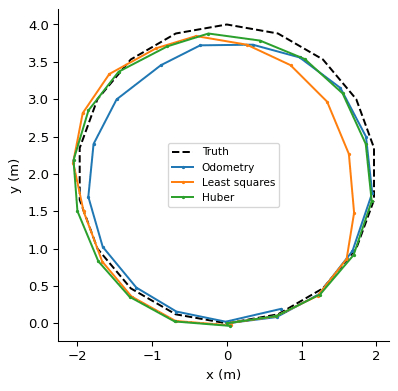

In [2]:
rng = np.random.default_rng(61)
angles = np.linspace(0, 2 * np.pi, 19)
truth = np.c_[2 * np.sin(angles), 2 * (1 - np.cos(angles)), wrap(angles)]
u_std = np.array([0.045, 0.035, 0.035])
loop_std = np.array([0.05, 0.05, 0.04])
edges = []
od = [truth[0]]
for i in range(len(truth) - 1):
    z = between(truth[i], truth[i + 1]) + rng.normal(0, u_std) + [0.007, 0, 0.017]
    edges.append((i, i + 1, z, u_std))
    od.append(compose(od[-1], z))
for i, j in [(0, 18), (1, 17), (2, 16), (3, 15)]:
    edges.append((i, j, between(truth[i], truth[j]) + rng.normal(0, loop_std), loop_std))
edges.append((4, 14, between(truth[4], truth[14]) + [0.62, -0.58, 0.39], loop_std))
od = np.asarray(od)
plain = solve_graph(od, edges)
robust = solve_graph(od, edges, True)


def rms(x):
    return np.sqrt(np.mean(np.sum((x[:, :2] - truth[:, :2]) ** 2, axis=1)))


print(
    "Position RMSE (m), odometry / least squares / Huber",
    np.round([rms(q) for q in [od, plain, robust]], 3),
)
print(
    "Closure gap (m)",
    np.round([np.linalg.norm(q[0, :2] - q[-1, :2]) for q in [od, plain, robust]], 3),
)
assert np.allclose(robust[0], truth[0]) and rms(robust) < rms(od)
fig, ax = plt.subplots(figsize=(5.7, 4), constrained_layout=True)
for arr, label, style in [
    (truth, "Truth", "k--"),
    (od, "Odometry", ".-"),
    (plain, "Least squares", ".-"),
    (robust, "Huber", ".-"),
]:
    ax.plot(arr[:, 0], arr[:, 1], style, ms=3, label=label)
ax.set(aspect="equal", xlabel="x (m)", ylabel="y (m)")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The map is a graph of poses. Reliable closure detection is a separate front-end problem. Huber loss acts on the whitened scalar residuals in this implementation.

## Exercise

Remove the bad closure, then compare both estimation objectives again.

## References

[Grisetti et al., A Tutorial on Graph-Based SLAM](https://doi.org/10.1109/MITS.2010.939925)

[Dellaert and Hutchinson, SLAM](https://www.roboticsbook.org/S64_driving_perception.html)